![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Time slices, animation and stable scales

**Lesson 18 · Original synthetic data · Independent educational project**

## Objectives

Build comparable frames; measure field change rather than relying on motion.

[Previous](17-globe.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/18-time.ipynb) · [Next](19-dashboard.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=18-time.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

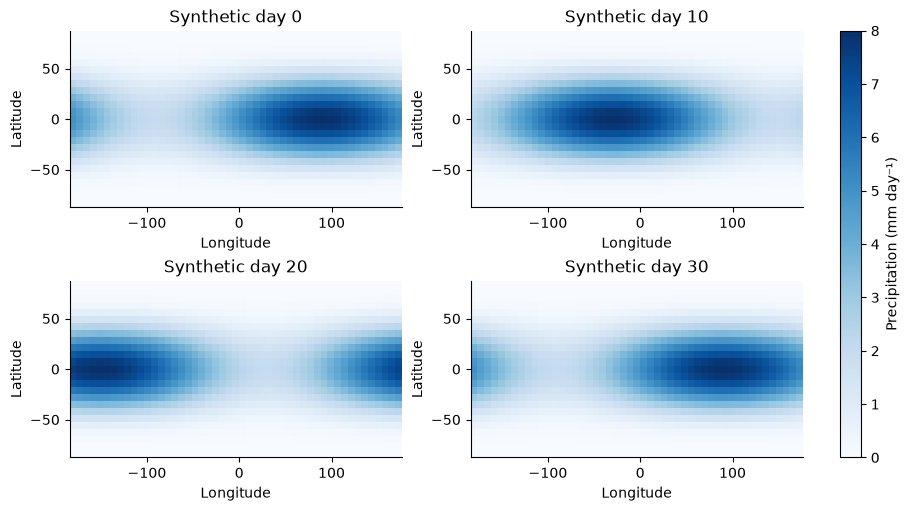

Mean absolute change after 10 days: 1.28 mm/day


In [2]:
cube = lab.synthetic_cube()
days = [0, 10, 20, 30]
fig, axes = plt.subplots(2, 2, figsize=(9, 5), constrained_layout=True)
for ax, day in zip(axes.flat, days):
    im = ax.pcolormesh(cube["lon"], cube["lat"], cube["precipitation"][day], shading="auto", vmin=0, vmax=8, cmap="Blues")
    ax.set(title=f"Synthetic day {day}", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(im, ax=axes, label="Precipitation (mm day⁻¹)")
plt.show()
assert np.allclose(cube["precipitation"][0], cube["precipitation"][30])
change = np.abs(cube["precipitation"][10] - cube["precipitation"][0]).mean()
print(f"Mean absolute change after 10 days: {change:.2f} mm/day")

## Exercise

Try days 5, 15, 25 and 35. Use the live gallery time slider to compare moving patterns with these static frames.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interactive Lab experiment

Move the time slider, change the variable or rotate the 3D view. This widget runs in a Python kernel in Lab; the published book preserves a static output. Explain which control changes the data and which only changes its display.

In [3]:
import ipywidgets as widgets
from IPython.display import display
interactive_cube = lab.synthetic_cube(nlat=19, nlon=31)
def explore(day=0, variable="temperature", azimuth=-55):
    units = interactive_cube["units"][variable]
    field = interactive_cube[variable][day]
    bounds = (245, 300) if variable == "temperature" else (0, 8)
    fig = plt.figure(figsize=(8, 4))
    ax = fig.add_subplot()
    im = ax.pcolormesh(interactive_cube["lon"], interactive_cube["lat"], field, shading="auto", vmin=bounds[0], vmax=bounds[1])
    fig.colorbar(im, ax=ax, label=units)
    ax.set(xlabel="Longitude", ylabel="Latitude")
    fig.suptitle(f"Synthetic {variable}, day {day}")
    plt.tight_layout(); plt.show()
controls = widgets.interactive(explore, day=widgets.IntSlider(min=0,max=59,value=0),
                               variable=["temperature", "precipitation"], azimuth=widgets.fixed(-55))
display(controls)

interactive(children=(IntSlider(value=0, description='day', max=59), Dropdown(description='variable', options=…

## Interpretation and limits

The generator has a 30-day periodic precipitation cycle. Repetition follows an equation chosen for teaching; it is not a discovered atmospheric oscillation.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://matplotlib.org/stable/api/animation_api.html) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).